# Cómo BERTopic convierte reseñas en tópicos

VOC ya tiene textos preparados y embeddings. A partir de ellos, **BERTopic** organiza un recorrido modular: reduce dimensiones, descubre grupos y extrae términos que ayudan a describirlos. En esta libreta seguirás qué entra, qué cambia y qué sale en cada fase, usando la ejecución G0 de 1.000 registros como ejemplo.

Usarás las mismas funciones Python que invocan los CLI de VOC, sin ejecutar comandos de terminal desde la libreta. Primero recuperarás los vectores de entrada. Después inspeccionarás UMAP y HDBSCAN y reconstruirás los conteos y pesos de c-TF-IDF. Finalmente volverás a las reseñas y exportarás figuras. **Run All no vuelve a ajustar UMAP ni HDBSCAN**: carga sus salidas verificadas. Sí realiza cálculos didácticos de distancias y reconstruye la representación léxica de los mismos grupos. No genera embeddings ni llama a un LLM.

| Fase | Entrada | Transformación | Salida de G0 |
| --- | --- | --- | --- |
| Embeddings existentes | Textos preparados | Lectura de vectores MiniLM ya calculados | 1.000 × 384 |
| UMAP | Vectores semánticos | Vecindarios y representación de menor dimensión | 1.000 × 5 |
| HDBSCAN | Coordenadas reducidas | Densidad, jerarquía y selección de grupos | Una asignación por registro, o `-1` |
| Vectorización | Textos reunidos por grupo | Conteo de palabras y bigramas | Matriz grupo × término |
| c-TF-IDF | Conteos por grupo | Ponderación de términos | Palabras y pesos por tópico |

Los gráficos de coordenadas y palabras proceden de G0. El pequeño ejemplo de densidad utiliza puntos inventados y solo explica el mecanismo.


## 1. Abriendo una ejecución verificada

Usa el kernel del Operador y ejecuta esta celda. Las rutas se resuelven desde la configuración de VOC. El identificador y la huella fijan la ejecución que leerás, sin elegir automáticamente la más reciente.


In [53]:
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from voc.paths import data_root
from voc.topics import read_topics
from voc_ml.topics import TopicConfig

RUN_ID = "7ce4db4a-2890-4489-ac14-d1bf0a5ad35d"
MANIFEST_SHA256 = "902f2b1e9ea240136deecec7e375c38457ee036f2a5120e769b28596d26aeea4"
release = data_root() / "topics/runs" / RUN_ID / "release"
bundle = read_topics(release, manifest_sha256=MANIFEST_SHA256)
inputs = bundle.info["input"]
config = bundle.info["configuration"]
topic_config = TopicConfig(**config)
counts = bundle.info["counts"]

print("Ejecución:", RUN_ID)
print("Dataset:", inputs["dataset"]["artifact_id"])
print("Registros:", counts["rows"])
print("Integridad, asignaciones y evidencia: verificadas")


Ejecución: 7ce4db4a-2890-4489-ac14-d1bf0a5ad35d
Dataset: 3862e53a-e9f4-47af-a644-35c2cc7c1945
Registros: 1000
Integridad, asignaciones y evidencia: verificadas


El lector verifica hashes, orden, tamaños y pertenencia de los ejemplos a sus tópicos. Los resultados son archivos portables, por lo que no necesitas recuperar un objeto BERTopic serializado ni contactar a ZenML o MLflow para consultarlos.

## 2. Conservando la relación entre textos y vectores

La población contiene 84.479 registros y sus embeddings de 384 dimensiones. El perfil `minilm-verbatim-v1` conserva `model_text` como entrada del encoder y produce vectores normalizados. Esta ejecución reutilizó esos embeddings, no generó otros.

La muestra se seleccionó sin reemplazo, proporcionalmente por **plataforma y mes**, con semilla 42. Las cuotas se redondean por restos mayores. Los estratos pequeños pueden quedar sin registros seleccionados. Los meses se derivan de las fechas disponibles, cuyo significado varía entre fuentes. Se conservan registros distintos con texto repetido, por lo que la muestra tampoco representa 1.000 personas o textos necesariamente diferentes.


In [54]:
coverage = pd.DataFrame(inputs["coverage"])
source_counts = coverage.groupby("platform")[["population", "selected"]].sum()
source_counts["porcentaje_muestra"] = 100 * source_counts.selected / counts["rows"]
display(source_counts)
print("Textos distintos en la muestra:", bundle.reviews.model_text.nunique())
print("Estratos sin representación:", int(coverage.selected.eq(0).sum()))
print("SHA-256 de la selección:", inputs["selection_sha256"])


,population,selected,porcentaje_muestra
platform,,,
app_store,5623,67,6.7
google_play,70975,839,83.9
x,6553,78,7.8
youtube,1328,16,1.6


Textos distintos en la muestra: 847
Estratos sin representación: 1
SHA-256 de la selección: 83158ce824ee6b47591774cf5b06e8e9beaa5fbf4d4ee1218753d73efbac6e52


Cada fila conserva `record_id`, `model_text`, `platform`, `record_date`, `period` y `source_row`. Este último identifica su posición en la entrada verificada y permite seleccionar el vector correspondiente. La asignación conserva exactamente ese orden.


In [55]:
assert bundle.reviews.record_id.tolist() == bundle.assignments.record_id.tolist()
assert bundle.coordinates.shape == (counts["rows"], config["n_components"])
display(bundle.reviews.drop(columns="model_text").head(3))


,record_id,platform,record_date,source_row,period
0,appbot:498483038:3610086576,app_store,2025-09-02,28,2025-09
1,appbot:498483038:3614072897,app_store,2025-09-14,140,2025-09
2,appbot:498483038:3618300367,app_store,2025-09-21,208,2025-09


## 3. Recorriendo las fases de BERTopic

**BERTopic coordina componentes**, no es una única red que transforma directamente una reseña en un nombre de tópico. En G0, los embeddings ya están calculados. UMAP y HDBSCAN forman los grupos y c-TF-IDF los describe mediante términos. La siguiente tabla recupera los parámetros usados, sin sustituirlos por valores nuevos.


In [56]:
parameters = pd.DataFrame([
    ("Muestra", "Tamaño / semilla", f"{config['sample_size']} / {config['sample_seed']}"),
    ("UMAP", "Vecinos / dimensiones", f"{config['n_neighbors']} / {config['n_components']}"),
    ("UMAP", "Distancia mínima / semilla", f"{config['min_dist']} / {config['random_state']}"),
    ("HDBSCAN", "Tamaño mínimo / min_samples", f"{config['min_cluster_size']} / {config['min_samples']}"),
    ("HDBSCAN", "Selección de grupos", config["cluster_selection_method"]),
    ("c-TF-IDF", "Máximo de palabras por grupo", str(config["top_n_words"])),
], columns=["componente", "parámetro", "valor"])
display(parameters)
print("Palabras vacías:", ", ".join(bundle.execution["fit"]["representation"]["stop_words"]))


,componente,parámetro,valor
0,Muestra,Tamaño / semilla,1000 / 42
1,UMAP,Vecinos / dimensiones,15 / 5
2,UMAP,Distancia mínima / semilla,0.0 / 42
3,HDBSCAN,Tamaño mínimo / min_samples,10 / 3
4,HDBSCAN,Selección de grupos,eom
5,c-TF-IDF,Máximo de palabras por grupo,10


Palabras vacías: a, al, con, de, del, el, ella, en, es, esta, este, ha, la, las, lo, los, me, mi, mis, para, por, que, se, su, sus, un, una, unas, unos, y, yo


### 3.1. Entrada: una fila de texto, una fila de vector

Carga la matriz de trabajo que utilizó el productor. Su huella está fijada en el manifiesto del resultado y permite detectar cambios. La función `read_run_input` aplica la misma validación de entradas que utiliza el productor antes de exportar. Necesitas conservar `run.json` y los archivos de `work/` junto al release para esta parte didáctica. La consulta ordinaria de tópicos sigue necesitando únicamente el release.

El modelo MiniLM había convertido cada `model_text` en 384 valores normalizados. Aquí **no entrenamos ni ejecutamos el encoder**. Cada coordenada forma parte de una representación aprendida, no corresponde a una categoría como «acceso» o «transferencia».


In [57]:
from voc_ml.topics.production import read_run_input
from voc_ml.topics.store import TopicRunStore

# El mismo lector que usa finish_run valida texto, orden y huella de los vectores.
run_store = TopicRunStore(data_root())
pinned_input = read_run_input(RUN_ID, store=run_store)
assert pinned_input.info == inputs
assert pinned_input.reviews.record_id.tolist() == bundle.reviews.record_id.tolist()
X = pinned_input.vectors

print("Entrada verificada:", X.shape)
display(pd.DataFrame(X[:3, :6], columns=[f"x{i+1}" for i in range(6)]))


Entrada verificada: (1000, 384)


,x1,x2,x3,x4,x5,x6
0,-0.018039,0.029986,-0.095083,-0.018727,0.006002,0.015151
1,-0.036220,0.040945,-0.008057,-0.050690,0.014881,-0.007073
2,0.003822,-0.036627,0.015574,0.007046,0.036485,-0.107182


**Comprueba:** hay 1.000 filas y 384 coordenadas por fila. Los seis valores mostrados son solo un fragmento, no los atributos completos.

### 3.2. UMAP: conservar relaciones de vecindad en menos dimensiones

UMAP comienza buscando vecinos en el espacio original y construye un grafo de relaciones con pesos. Después optimiza posiciones en un espacio de menor dimensión para aproximar esas relaciones. Conserva información de vecindad de forma aproximada, sin garantizar que todas las distancias o grupos permanezcan iguales.

En G0, `n_neighbors=15` controla la escala del vecindario, `n_components=5` fija la dimensión de salida y `min_dist=0` permite disposiciones compactas. Estas elecciones afectan la geometría que recibirá HDBSCAN. La semilla fija las condiciones aleatorias, aunque versiones o entornos distintos pueden producir diferencias.

Construye el objeto con `build_reducer`, la misma función que utiliza el ajuste de VOC. `get_params()` permite inspeccionar los parámetros de la ejecución. La llamada de ajuste se muestra comentada porque sus coordenadas ya están guardadas.


In [58]:
from voc_ml.topics.models import build_reducer

reducer = build_reducer(topic_config)
display(pd.Series({key: reducer.get_params()[key] for key in [
    "n_neighbors", "n_components", "min_dist", "metric", "random_state"
]}, name="configuración UMAP").to_frame())
# En producción: Y = reducer.fit_transform(X)
Y = bundle.coordinates
assert Y.shape == (X.shape[0], config["n_components"])
print("Transformación guardada:", X.shape, "→", Y.shape)
display(pd.DataFrame(Y[:3], columns=[f"UMAP {i+1}" for i in range(Y.shape[1])]))


,configuración UMAP
n_neighbors,15
n_components,5
min_dist,0.0
metric,cosine
random_state,42


Transformación guardada: (1000, 384) → (1000, 5)


,UMAP 1,UMAP 2,UMAP 3,UMAP 4,UMAP 5
0,-0.178256,1.584364,0.353346,7.892000,2.846358
1,-0.064651,1.799756,0.120540,10.312610,3.083537
2,0.177882,3.465701,0.751980,10.049823,2.827368


Ahora elige un registro y compara sus cinco vecinos más cercanos antes y después de reducir. Se usa coseno en los 384 valores originales y distancia euclídea en las cinco coordenadas, como en el recorrido de producción. **Las magnitudes de ambas distancias no tienen la misma escala**. La tabla permite observar cambios de vecinos en un caso, no evaluar toda la reducción.


In [59]:
QUERY_ROW = 0  # Cambia este índice para estudiar otra reseña de la misma muestra.
assert 0 <= QUERY_ROW < len(X)
cosine_distances = np.clip(1 - X @ X[QUERY_ROW], 0, 2)
reduced_distances = np.linalg.norm(Y - Y[QUERY_ROW], axis=1)
cosine_distances[QUERY_ROW] = np.inf
reduced_distances[QUERY_ROW] = np.inf
original_neighbors = np.argsort(cosine_distances, kind="stable")[:5]
reduced_neighbors = np.argsort(reduced_distances, kind="stable")[:5]
neighbor_comparison = pd.DataFrame({
    "posición": np.arange(1, 6),
    "fila_en_384D": original_neighbors,
    "distancia_coseno": cosine_distances[original_neighbors],
    "fila_en_5D": reduced_neighbors,
    "distancia_euclídea": reduced_distances[reduced_neighbors],
})
print("Registro consultado:", bundle.reviews.iloc[QUERY_ROW].record_id)
display(neighbor_comparison.round(4))
print("Vecinos compartidos:", len(set(original_neighbors) & set(reduced_neighbors)), "de 5")


Registro consultado: appbot:498483038:3610086576


,posición,fila_en_384D,distancia_coseno,fila_en_5D,distancia_euclídea
0,1,650,0.3512,650,0.0340
1,2,782,0.3576,447,0.0363
2,3,671,0.3810,454,0.0780
3,4,447,0.3869,227,0.0833
4,5,454,0.3902,118,0.1528


Vecinos compartidos: 3 de 5


**Comprueba:** el número de filas permanece igual y cambia su representación. Si cambia algún vecino, no significa por sí solo que la reducción haya fallado. La compresión pierde información y debe evaluarse según su uso.

### 3.3. HDBSCAN: de distancias a grupos

HDBSCAN estima densidad local a partir de las distancias a vecinos. Combina esas distancias en una medida de **alcanzabilidad mutua**, construye un árbol de conexiones y deriva una jerarquía de grupos. La condensa usando un tamaño mínimo y selecciona grupos mediante un criterio de estabilidad dentro de esa jerarquía, `eom`. Esa estabilidad interna no demuestra reproducibilidad entre muestras o semillas.

En G0, `min_cluster_size=10` fija el tamaño mínimo de un grupo y `min_samples=3` interviene en la estimación de densidad. El número de tópicos no se decide de antemano. Los puntos que no reciben un grupo conservan `-1`.

Para entender la primera operación, usa estos puntos **inventados**. El radio hasta el tercer vecino distinto del propio punto será pequeño en una zona compacta y grande para un punto aislado.


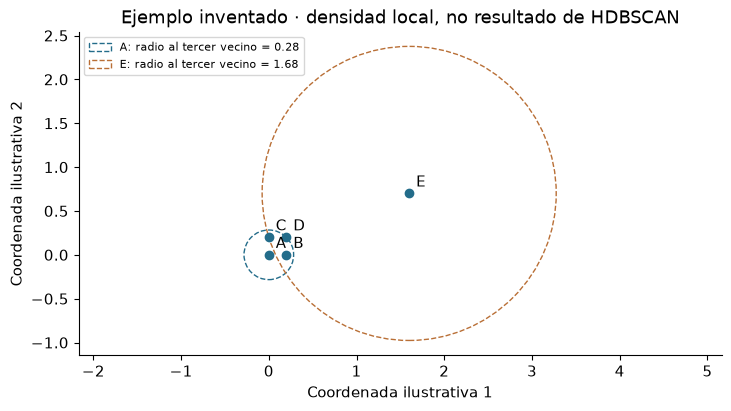

,punto,radio_tercer_vecino
0,A,0.283
1,B,0.283
2,C,0.283
3,D,0.283
4,E,1.676


Alcanzabilidad mutua D–E = max(0.283, 1.676, 1.487) = 1.676


In [60]:
from matplotlib.patches import Circle

points = np.array([[0, 0], [0.2, 0], [0, 0.2], [0.2, 0.2], [1.6, 0.7]])
names = np.array(["A", "B", "C", "D", "E"])
distances = np.linalg.norm(points[:, None, :] - points[None, :, :], axis=2)
np.fill_diagonal(distances, np.inf)
k = 3
core_distance = np.sort(distances, axis=1)[:, k - 1]
direct_DE = np.linalg.norm(points[3] - points[4])
reach_DE = max(core_distance[3], core_distance[4], direct_DE)

fig_density, ax = plt.subplots(figsize=(7.2, 4), layout="constrained")
ax.scatter(*points.T, color="#236C8A", zorder=3)
for i, label in enumerate(names):
    ax.annotate(label, points[i], xytext=(5, 5), textcoords="offset points")
for i, color in [(0, "#236C8A"), (4, "#B96F36")]:
    ax.add_patch(Circle(points[i], core_distance[i], fill=False, color=color,
                        linestyle="--", label=f"{names[i]}: radio al tercer vecino = {core_distance[i]:.2f}"))
ax.autoscale_view()
ax.set_aspect("equal", adjustable="datalim")
ax.set_title("Ejemplo inventado · densidad local, no resultado de HDBSCAN")
ax.set_xlabel("Coordenada ilustrativa 1")
ax.set_ylabel("Coordenada ilustrativa 2")
ax.legend(loc="upper left", fontsize=8)
plt.show()
display(pd.DataFrame({"punto": names, "radio_tercer_vecino": core_distance}).round(3))
print(f"Alcanzabilidad mutua D–E = max({core_distance[3]:.3f}, {core_distance[4]:.3f}, {direct_DE:.3f}) = {reach_DE:.3f}")


La alcanzabilidad mutua toma el máximo entre los dos radios locales y la distancia del par. Así, una conexión con una zona poco densa puede resultar menos cercana que su distancia geométrica por sí sola. Este ejemplo calcula distancias, **no ejecuta la construcción de la jerarquía ni produce etiquetas HDBSCAN**.

Vuelve ahora a G0. El objeto siguiente muestra la configuración del agrupamiento real. Recuperamos las etiquetas guardadas y la correspondencia que BERTopic registró al renumerar los grupos. Las etiquetas numéricas no tienen significado semántico propio.


In [61]:
from voc_ml.topics.models import build_clusterer

clusterer = build_clusterer(topic_config)
display(pd.Series({key: clusterer.get_params()[key] for key in [
    "min_cluster_size", "min_samples", "metric", "cluster_selection_method"
]}, name="configuración HDBSCAN").to_frame())
# En producción: clusterer.fit(Y), seguido del mapeo de etiquetas de BERTopic.
topic_labels = bundle.assignments.topic_id.to_numpy()
mapping = pd.DataFrame(bundle.execution["fit"]["cluster_to_topic"])
assert mapping.cluster_id.is_unique and mapping.topic_id.is_unique
assert len(topic_labels) == len(Y)
print("Registros con tópico:", int((topic_labels != -1).sum()))
print("Registros sin asignación:", int((topic_labels == -1).sum()))
display(mapping.head(6))


,configuración HDBSCAN
min_cluster_size,10
min_samples,3
metric,euclidean
cluster_selection_method,eom


Registros con tópico: 838
Registros sin asignación: 162


,cluster_id,topic_id
0,-1,-1
1,0,2
2,1,3
3,2,14
4,3,30
5,4,26


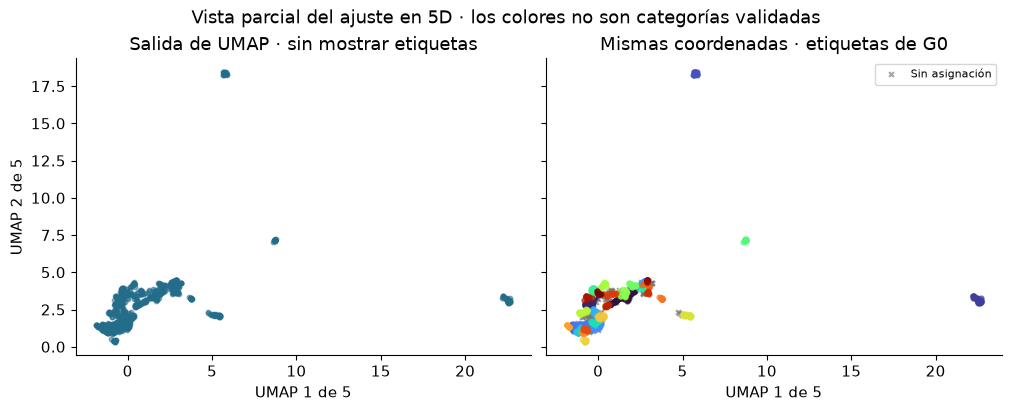

In [62]:
# Dos coordenadas guardadas se muestran antes y después de colorear las etiquetas.
# El ajuste utilizó las cinco dimensiones, no solo estas dos.
fig_grouping, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True, layout="constrained")
axes[0].scatter(Y[:, 0], Y[:, 1], s=10, alpha=0.5, color="#236C8A")
axes[0].set_title("Salida de UMAP · sin mostrar etiquetas")
for topic_id in sorted(set(topic_labels)):
    mask = topic_labels == topic_id
    axes[1].scatter(Y[mask, 0], Y[mask, 1], s=12, alpha=0.65,
                    marker="x" if topic_id == -1 else "o",
                    color="#777777" if topic_id == -1 else plt.get_cmap("turbo")((topic_id % 35) / 34),
                    label="Sin asignación" if topic_id == -1 else None)
axes[1].set_title("Mismas coordenadas · etiquetas de G0")
axes[1].legend(fontsize=8)
for ax in axes:
    ax.set_xlabel("UMAP 1 de 5")
axes[0].set_ylabel("UMAP 2 de 5")
fig_grouping.suptitle("Vista parcial del ajuste en 5D · los colores no son categorías validadas")
plt.show()


**Comprueba:** colorear no mueve los puntos. Un solapamiento en estos dos ejes no demuestra que dos grupos coincidan en las cinco dimensiones. La figura es una vista parcial, no un nuevo UMAP de dos dimensiones. Los 162 casos sin asignación tampoco son automáticamente irrelevantes.

### 3.4. Vectorización: reunir textos y contar términos

Después de agrupar, volvemos a los textos. BERTopic reúne las reseñas de cada grupo en un documento agregado y `CountVectorizer` cuenta sus términos. Esta representación léxica es distinta del embedding semántico.

G0 utiliza minúsculas, tokens de al menos dos caracteres, una lista de palabras vacías y unigramas y bigramas. La negación «no» se conserva. Observa primero el resultado sobre una frase inventada.


In [63]:
from voc_ml.topics.models import build_vectorizer

# Reutiliza la fábrica de producción con la política registrada en G0.
representation = bundle.execution["fit"]["representation"]
vectorizer = build_vectorizer(representation)
sentence = "La aplicación no abre y no puedo entrar."
print("Entrada inventada:", sentence)
print("Términos contados:", vectorizer.build_analyzer()(sentence))


Entrada inventada: La aplicación no abre y no puedo entrar.
Términos contados: ['aplicación', 'no', 'abre', 'no', 'puedo', 'entrar', 'aplicación no', 'no abre', 'abre no', 'no puedo', 'puedo entrar']


Los bigramas se forman después de retirar palabras vacías. Por eso no siempre son frases contiguas del texto original. Además, concatenar reseñas puede crear un bigrama entre el final de una y el principio de otra. Conviene revisar el contexto antes de usar un término como evidencia de una funcionalidad.

Reconstruye ahora los documentos agregados de G0, incluido el conjunto `-1` para conservar exactamente el cálculo léxico original. Este conjunto participa en los conteos aunque no se contabilice como tópico descubierto. Con `language="multilingual"`, BERTopic 0.17.4 sustituye saltos de línea y tabulaciones por espacios antes de vectorizar.


In [64]:
documents = pd.DataFrame({"topic_id": topic_labels, "text": bundle.reviews.model_text})
grouped_text = documents.groupby("topic_id", sort=True).text.agg(" ".join)
cleaned_text = [text.replace("\n", " ").replace("\t", " ") or "emptydoc" for text in grouped_text]
bow = vectorizer.fit_transform(cleaned_text)
terms = vectorizer.get_feature_names_out()
term_index = {term: i for i, term in enumerate(terms)}
print("Matriz de conteos, grupos × términos:", bow.shape)
print("Incluye la fila -1:", -1 in grouped_text.index)
illustrative_terms = [t for t in ["no", "no abre", "aplicación", "excelente"] if t in term_index]
columns = [term_index[t] for t in illustrative_terms]
display(pd.DataFrame(bow[:, columns].toarray(), index=grouped_text.index,
                     columns=illustrative_terms).head(6))


Matriz de conteos, grupos × términos: (36, 8653)
Incluye la fila -1: True


,no,no abre,aplicación,excelente
topic_id,,,,
-1,114,3,32,7
0,1,0,0,4
1,76,12,36,0
2,0,0,1,56
3,1,0,0,1
4,6,0,1,1


### 3.5. c-TF-IDF: del conteo al peso de una palabra

Contar no basta: un grupo grande puede dominar los recuentos. c-TF-IDF normaliza los conteos dentro de cada grupo y pondera los términos usando su frecuencia en el conjunto. Con la opción de G0 `reduce_frequent_words=True`, el peso es:

\[
w_{t,c}=\sqrt{\frac{n_{t,c}}{N_c}}\,\log\left(1+\frac{A}{f_t}\right).
\]

Aquí, \(n_{t,c}\) cuenta el término \(t\) en el grupo \(c\), \(N_c\) suma los conteos de ese grupo y \(f_t\) suma los del término en todos los grupos. \(A\) es el promedio de conteos por grupo, convertido a entero en BERTopic 0.17.4. Los conteos incluyen unigramas y bigramas, no solo palabras del texto original.

La raíz cuadrada reduce el predominio relativo de las frecuencias altas frente a usar la frecuencia normalizada sin esa opción. El factor logarítmico disminuye al crecer la frecuencia global del término. Estos pesos no son probabilidades ni medidas de sentimiento. Calcula los pesos y contrástalos tanto con `ClassTfidfTransformer` como con el artefacto guardado.


In [65]:
from voc_ml.topics.models import build_ctfidf

row_totals = np.asarray(bow.sum(axis=1)).ravel()
term_totals = np.asarray(bow.sum(axis=0)).ravel()
A = int(row_totals.mean())
idf = np.log1p(A / term_totals)
manual_weights = bow.astype(float).multiply((1 / row_totals)[:, None]).tocsr()
manual_weights.data = np.sqrt(manual_weights.data)
manual_weights = manual_weights.multiply(idf).tocsr()

ctfidf = build_ctfidf(representation)
library_weights = ctfidf.fit_transform(bow.copy())
delta = manual_weights - library_weights
assert delta.nnz == 0 or np.max(np.abs(delta.data)) < 1e-10

# Compara los términos guardados de todos los grupos sin cambiar sus integrantes.
for saved_topic in bundle.topics:
    row = grouped_text.index.get_loc(saved_topic["topic_id"])
    for keyword in saved_topic["keywords"]:
        weight = manual_weights[row, term_index[keyword["term"]]]
        assert np.isclose(weight, keyword["weight"], rtol=1e-6, atol=1e-8)
print("Fórmula, biblioteca y pesos guardados: coinciden.")


Fórmula, biblioteca y pesos guardados: coinciden.


Promedio entero de conteos por grupo, A = 484


,término,conteo_en_grupo,total_en_grupo,conteo_global,idf,peso_calculado,peso_guardado
0,abrir aplicación,8,1799,10,3.89995,0.26007,0.26007
1,cierra,8,1799,10,3.89995,0.26007,0.26007
2,no abre,12,1799,22,3.13549,0.25608,0.25608
3,entrar,20,1799,49,2.38670,0.25165,0.25165
4,abre,13,1799,28,2.90612,0.24704,0.24704
5,deja entrar,8,1799,13,3.64364,0.24298,0.24298
6,entrar app,7,1799,11,3.80666,0.23745,0.23745
7,abrir,14,1799,37,2.64483,0.23332,0.23332
8,aplicación no,7,1799,12,3.72167,0.23215,0.23215
9,tarda,9,1799,20,3.22684,0.22824,0.22824


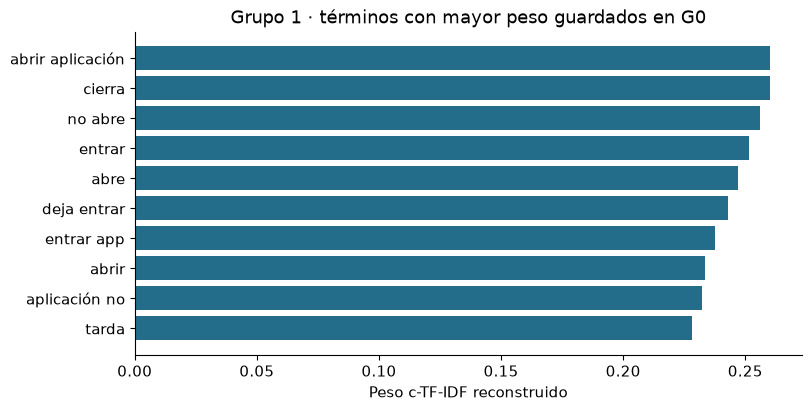

In [66]:
TOPIC_TO_EXPLAIN = 1  # Puedes elegir otro ID de los grupos guardados.
topic = bundle.topic(TOPIC_TO_EXPLAIN)
row = grouped_text.index.get_loc(TOPIC_TO_EXPLAIN)
term_calculation = pd.DataFrame([
    {"término": word["term"],
     "conteo_en_grupo": int(bow[row, term_index[word["term"]]]),
     "total_en_grupo": int(row_totals[row]),
     "conteo_global": int(term_totals[term_index[word["term"]]]),
     "idf": float(idf[term_index[word["term"]]]),
     "peso_calculado": float(manual_weights[row, term_index[word["term"]]]),
     "peso_guardado": word["weight"]}
    for word in topic["keywords"]
])
print("Promedio entero de conteos por grupo, A =", A)
display(term_calculation.round(5))

fig_terms, ax = plt.subplots(figsize=(8, 4), layout="constrained")
ax.barh(term_calculation["término"], term_calculation.peso_calculado, color="#236C8A")
ax.invert_yaxis()
ax.set_xlabel("Peso c-TF-IDF reconstruido")
ax.set_title(f"Grupo {TOPIC_TO_EXPLAIN} · términos con mayor peso guardados en G0")
plt.show()


**Comprueba:** el peso puede reconstruirse a partir de conteos y coincide con el guardado. Modificar la lista de palabras vacías o el uso de bigramas cambiaría la descripción sin obligar a modificar los grupos. Las palabras son indicios del asunto, todavía no un nombre validado.

### 3.6. Conectando las piezas en BERTopic

La función `build_topic_model` ensambla los componentes que acabamos de estudiar. Es la misma que llama `discover` cuando ejecutamos `voc-ml topics workflow`. Construir el objeto no ejecuta el ajuste. En producción, `fit_transform` recibe textos y embeddings alineados y coordina UMAP, HDBSCAN y la representación léxica. El bloque anterior reconstruyó únicamente esta última sobre grupos fijos.


In [67]:
from voc_ml.topics.models import build_topic_model

model_configuration = build_topic_model(topic_config, policy=representation)
# discover() utiliza este ensamblaje. Aquí solo lo construimos e inspeccionamos.
# Llamada de producción mostrada, no ejecutada por esta libreta:
# labels, strengths = model_configuration.fit_transform(
#     bundle.reviews.model_text.tolist(), embeddings=X
# )
print("Componentes conectados. No se inició otro ajuste.")


Componentes conectados. No se inició otro ajuste.


Por último, BERTopic aproxima ejemplos representativos comparando representaciones c-TF-IDF de comentarios candidatos con la del grupo. No vuelve a calcular embeddings semánticos para esa selección. VOC conserva referencias a los textos escogidos y comprueba que pertenecen a su grupo. Más adelante revisarás esos ejemplos y sus límites.

## 4. Midiendo cobertura y tamaños

Después de entender el recorrido, observa el resultado de G0. Un tópico es un grupo descubierto en esta muestra. El número de grupos y la proporción sin asignación describen la salida, pero no prueban que cada grupo identifique un problema útil para el negocio.


In [68]:
topic_table = pd.DataFrame([
    {"topic_id": t["topic_id"], "registros": t["size"],
     "palabras": ", ".join(k["term"] for k in t["keywords"]),
     "ejemplos_disponibles": len(t["evidence_ids"])}
    for t in bundle.topics
]).sort_values(["registros", "topic_id"], ascending=[False, True])
assigned = topic_table[topic_table.topic_id.ne(-1)].copy()
summary = pd.DataFrame([
    ("Registros seleccionados", counts["rows"]),
    ("Tópicos, excluyendo -1", counts["topic_count"]),
    ("Registros agrupados", counts["rows"] - counts["unassigned_rows"]),
    ("Registros sin asignación", counts["unassigned_rows"]),
    ("Porcentaje sin asignación", 100 * counts["unassigned_fraction"]),
], columns=["medida", "valor"])
display(summary)
display(topic_table.head(8))


,medida,valor
0,Registros seleccionados,1000.0
1,"Tópicos, excluyendo -1",35.0
2,Registros agrupados,838.0
3,Registros sin asignación,162.0
4,Porcentaje sin asignación,16.2


,topic_id,registros,palabras,ejemplos_disponibles
0,-1,162,"banamex, sucursal, https co, https, transferen...",3
1,0,65,"rápida, rápido, eficiente, muy rápido, práctic...",3
2,1,61,"abrir aplicación, cierra, no abre, entrar, abr...",3
3,2,59,"excelente excelente, excelente, excelente geni...",2
4,3,43,"buena muy, muy buena, buena, ago, transferenci...",3
5,4,37,"app muy, buena app, bien app, mucho app, app s...",3
6,5,33,"muy fácil, fácil usar, fácil, usar, sencilla, ...",3
7,6,33,"tarjetas, saldo, no permite, permite ver, tarj...",3


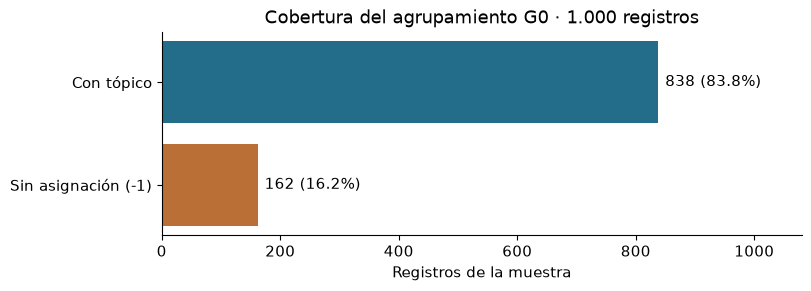

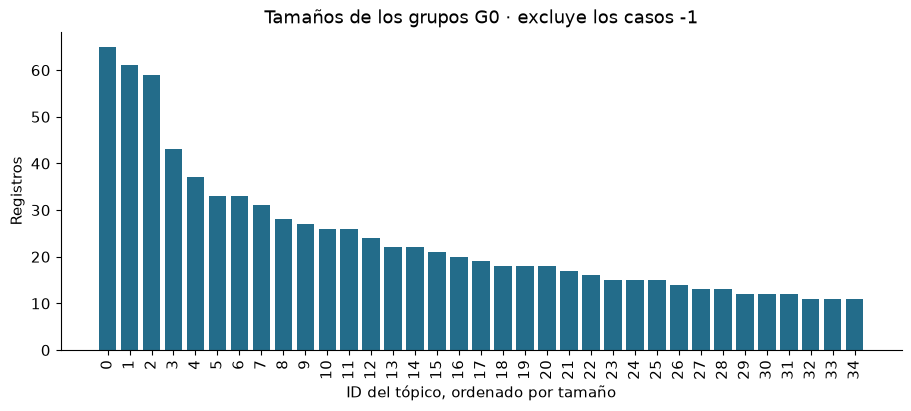

In [69]:
plt.rcParams.update({"font.size": 11, "axes.spines.top": False, "axes.spines.right": False})
fig_assignment, ax = plt.subplots(figsize=(8, 2.8), layout="constrained")
values = [counts["rows"] - counts["unassigned_rows"], counts["unassigned_rows"]]
bars = ax.barh(["Con tópico", "Sin asignación (-1)"], values, color=["#236C8A", "#B96F36"])
ax.bar_label(bars, labels=[f"{v:,} ({v / counts['rows']:.1%})" for v in values], padding=5)
ax.set_xlim(0, counts["rows"] * 1.08)
ax.set_xlabel("Registros de la muestra")
ax.set_title("Cobertura del agrupamiento G0 · 1.000 registros")
ax.invert_yaxis()
plt.show()

fig_sizes, ax = plt.subplots(figsize=(9, 4), layout="constrained")
if len(assigned):
    ax.bar(np.arange(len(assigned)), assigned.registros, color="#236C8A")
    ax.set_xticks(np.arange(len(assigned)), assigned.topic_id.astype(str), rotation=90)
else:
    ax.text(0.5, 0.5, "Sin tópicos asignados", ha="center", transform=ax.transAxes)
ax.set_xlabel("ID del tópico, ordenado por tamaño")
ax.set_ylabel("Registros")
ax.set_title("Tamaños de los grupos G0 · excluye los casos -1")
plt.show()


## 5. Volviendo a los comentarios

La revisión fijada antes del ajuste incluye los tres grupos mayores y hasta tres adicionales elegidos con semilla 42. Se muestran hasta tres textos distintos por grupo, seleccionados por BERTopic como representantes c-TF-IDF. Son ejemplos para inspección, no una muestra aleatoria ni una evaluación representativa de todos los comentarios del tópico.

Anota si comparten un asunto, mezclan funcionalidades o no permiten una interpretación clara. Una palabra frecuente como «excelente» puede describir valoración general sin identificar una funcionalidad concreta.


In [70]:
largest = assigned.topic_id.head(3).astype(int).tolist()
remaining = sorted(set(assigned.topic_id.astype(int)) - set(largest))
rng = np.random.default_rng(42)
additional = sorted(rng.choice(remaining, size=min(3, len(remaining)), replace=False).tolist())
review_ids = largest + additional
review_rows = []
for topic_id in review_ids:
    topic = bundle.topic(topic_id)
    for example in topic["evidence"][:3]:
        review_rows.append({
            "topic_id": topic_id, "record_id": example["record_id"],
            "platform": example["platform"], "model_text": example["model_text"],
            "observacion_humana": "",
        })
review = pd.DataFrame(review_rows, columns=[
    "topic_id", "record_id", "platform", "model_text", "observacion_humana"
])
print("Grupos para revisar:", review_ids)
with pd.option_context("display.max_colwidth", 180):
    display(review)


Grupos para revisar: [0, 1, 2, 5, 23, 26]


,topic_id,record_id,platform,model_text,observacion_humana
0,0,play:com.citibanamex.banamexmobile:cbbd8ff5-2134-449e-a54f-5935afe77741,google_play,fácil acceso permite hacer movimientos y transferencias a cualquier hora 24/7,
1,0,play:com.citibanamex.banamexmobile:ae2cca7a-a301-466e-beea-8bbc4b2383ad,google_play,Fácil de acceder y efectuar movimientos...buena plataforma estoy satisfecho...Buena... excelente...,
2,0,appbot:498483038:3680952085,app_store,Es fácil y súper rápido hacer transferencias cuando das de alta la cuenta.,
3,1,play:com.citibanamex.banamexmobile:cd7a8ac2-9db4-4f8e-8c93-8008bdd7b392,google_play,Es util la app se pueden hacer varios movimientos y ya no acudir al banco pero esta fallando mucho yo pensé que era por falta de actualización pero no ya llevo más de una seman...,
4,1,play:com.citibanamex.banamexmobile:faaf7970-a7f8-44d9-b6c9-bd80b2789e6a,google_play,"la no me permite escribir ni mi número de cuenta ni tampoco códigos de recuperación, ya se reinstalo la app se actualizo el equipo, mi equipo es de nueva generación no es antig...",
5,1,play:com.citibanamex.banamexmobile:9aeb9e5f-4a4b-4bfd-af43-147a58a8c38b,google_play,"Era Muy práctica y eficiente, y rápida la aplicación cuando era Citi, ahora que es Banamex no puedo abrir la aplicación se tarda bastante y cuando logro entrar se cierra, malís...",
6,2,play:com.citibanamex.banamexmobile:058b6b5b-a41b-4d7b-b672-d38ca577b077,google_play,Excelente,
7,2,play:com.citibanamex.banamexmobile:0035bcf8-0c5a-42c0-9455-7abf3c6b6044,google_play,excelente,
8,5,play:com.citibanamex.banamexmobile:794902b5-9022-487b-afbb-39b8412926f5,google_play,ha sido muy práctico usar la app ya todo lo puedes realizar desde ahí sin complicaciones y de forma segura,
9,5,play:com.citibanamex.banamexmobile:d6a1a691-47f9-4a67-971e-d8bae5b42ee7,google_play,me parece más eficiente los cambios que a favor de uno hacen a través de las aplicaciones porque nos facilita muchas veces no ir al banco o hacer algún otro tipo de operaciones...,


In [71]:
# Lee cinco casos sin asignación, seleccionados de forma reproducible.
unassigned = bundle.reviews.loc[bundle.assignments.topic_id.eq(-1)]
outlier_review = unassigned.sample(n=min(5, len(unassigned)), random_state=42)
with pd.option_context("display.max_colwidth", 180):
    display(outlier_review[["record_id", "platform", "model_text"]])


,record_id,platform,model_text
996,youtube:-:UgyDArj6ue31b0FvciB4AaABAg,youtube,Yo tengo joy y la neta se paga mucho interes y quiero cancelarlo
827,play:com.citibanamex.banamexmobile:e82dbc4b-e655-43c3-a270-66248bc4c074,google_play,"Excelente app de Banamex, muy fácil de manejar y entender."
929,x:2003157763279716827,x,@banamex @cochinandra No sirve tu app resuélvelo primero y deja de robarnos.\n\n. https://t.co/ZQGht19XUG
366,play:com.citibanamex.banamexmobile:5f143d2a-c0e3-4395-8dce-8bfad66e2b68,google_play,"bien, falta un apartado del beneficiario. BBVA ya lo tiene en su app."
674,play:com.citibanamex.banamexmobile:bab600c2-f9ea-4be4-b386-f985e1d875ca,google_play,fácil manejo.


La fuerza de pertenencia guardada es una salida de HDBSCAN. No equivale a una probabilidad calibrada de que el tópico sea correcto ni a una etiqueta de sentimiento. Tampoco todos los casos `-1` son irrelevantes: algunos pueden describir asuntos minoritarios o insuficientemente densos con esta configuración.

## 6. Reconociendo el alcance de la ejecución

El recorrido de producción validó las entradas, ejecutó un proceso de ajuste acotado y registró el resultado con ZenML y MLflow. El corte de diez minutos se aplica al proceso de ajuste, incluyendo su inicio e importaciones. En Linux se limita su afinidad a cuatro CPU disponibles y UMAP/HDBSCAN se configuran con un trabajador. El pico RSS corresponde solamente al proceso de ajuste, no es un límite de memoria ni una suma de todos los servicios.


In [72]:
execution = bundle.execution
print("ZenML:", execution["zenml_run_id"])
print("MLflow:", execution["mlflow_run_id"])
print("Tiempo del proceso de ajuste (s):", round(execution["worker_wall_seconds"], 3))
print("Pico RSS del proceso (GiB):", round(execution["fit"]["peak_worker_rss_bytes"] / 2**30, 3))
print("Identidad del código:", execution["code_identity"])
display(pd.Series(execution["fit"]["software"], name="versión").to_frame())


ZenML: 61662316-c602-4fcd-83d2-35025f9407ee
MLflow: 99b8c7af422a447d83520dd0a5d76ef8
Tiempo del proceso de ajuste (s): 16.614
Pico RSS del proceso (GiB): 1.097
Identidad del código: d9053a96ea6190974860716e4ab66e04fb2fb8385c4f8ba62a60f74fc47adf78


,versión
bertopic,0.17.4
hdbscan,0.8.44
numba,0.68.0
numpy,2.5.3
scikit-learn,1.9.1
scipy,1.18.1
umap-learn,0.5.12


Esta ejecución comprueba integración y trazabilidad sobre una muestra. No demuestra estabilidad entre semillas, una mejora frente al prototipo ni cobertura de todas las funcionalidades de la app. No se aplicaron sentimiento, filtro de relevancia o generación de etiquetas con LLM.

Para realizar otra ejecución se necesita iniciar expresamente `voc-ml topics workflow` con las referencias de dataset y embeddings y un archivo de configuración. Cambia después el identificador y la huella de esta libreta para leerla. Aquí no se lanza un nuevo ajuste.

**Reto:** identifica un grupo cuyas palabras sean genéricas. Revisa sus ejemplos y explica qué evidencia necesitarías antes de darle el nombre de una funcionalidad específica. Conserva fija la agrupación si después comparas representaciones de palabras.

## 7. Exportando evidencia para el artículo

Exportamos las tablas y figuras para preparar el reporte. Los ejemplos quedan en el directorio privado de datos para su revisión antes de publicar.


In [73]:
from datetime import datetime, timezone
from uuid import uuid4
from voc.datasets.shared.manifest import file_hash

export_dir = data_root() / "reports/topics" / (
    datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%SZ") + "-" + uuid4().hex[:8]
)
export_dir.mkdir(parents=True, exist_ok=False)
for name, figure in [
    ("asignacion_g0", fig_assignment), ("tamanos_g0", fig_sizes),
    ("densidad_didactica", fig_density), ("fases_agrupamiento_g0", fig_grouping),
    ("pesos_ctfidf_g0", fig_terms),
]:
    for extension in ("png", "pdf"):
        figure.savefig(export_dir / f"{name}.{extension}", dpi=180, bbox_inches="tight")
for name, table in [
    ("resumen", summary), ("topicos", topic_table), ("cobertura", coverage),
    ("configuracion", parameters), ("calculo_ctfidf", term_calculation),
    ("vecinos_384d_5d", neighbor_comparison), ("revision_ejemplos_privados", review),
    ("revision_sin_asignacion_privados", outlier_review),
]:
    table.to_csv(export_dir / f"{name}.csv", index=False)
manifest = {
    "run_id": RUN_ID, "topic_manifest_sha256": MANIFEST_SHA256,
    "dataset_artifact_id": inputs["dataset"]["artifact_id"],
    "selection_sha256": inputs["selection_sha256"],
    "notebook": "reports/topics/modelado-de-topicos-base.ipynb",
    "review_status": "pending_human_review",
    "vectors_sha256": inputs["vectors_sha256"],
    "query_row": QUERY_ROW,
    "topic_explained": TOPIC_TO_EXPLAIN,
    "figure_scope": {
        "densidad_didactica": "Puntos inventados, no resultado de HDBSCAN",
        "fases_agrupamiento_g0": "Dos coordenadas de las cinco de G0, sin nueva reducción",
        "pesos_ctfidf_g0": "Pesos reconstruidos sobre grupos fijos, verificados contra el artefacto",
    },
    "review_topic_ids": review_ids,
    "files": {p.name: file_hash(p) for p in sorted(export_dir.iterdir())},
}
(export_dir / "manifest.json").write_text(json.dumps(manifest, indent=2), encoding="utf-8")
print("Evidencia exportada a:", export_dir)


Evidencia exportada a: /workspace/data/reports/topics/20261103T175140Z-3c153f4a


## Referencias para continuar

- Alammar, J. y Grootendorst, M. (2024). *Hands-On Large Language Models*, capítulo 5, Text Clustering and Topic Modeling. O’Reilly.
- Grootendorst, M. (2022). *BERTopic: Neural topic modeling with a class-based TF-IDF procedure*. https://arxiv.org/abs/2203.05794

- [Documentación de UMAP: uso y reducción de dimensiones](https://umap-learn.readthedocs.io/en/latest/basic_usage.html).
- [Documentación de HDBSCAN: recorrido del algoritmo](https://hdbscan.readthedocs.io/en/latest/how_hdbscan_works.html).
- [Documentación de BERTopic: c-TF-IDF](https://maartengr.github.io/BERTopic/getting_started/ctfidf/ctfidf.html).

**Puntos clave:** conserva la relación entre texto y vector, distingue agrupamiento de representación, revisa los casos sin asignación y vincula cada ejemplo con su registro. La lectura de resultados guardados permite estudiar el método sin repetir su coste de ajuste.
